In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.5"

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline
import jax
jax.config.update("jax_enable_x64", True)  # Enable 64-bit precision

import jax.numpy as jnp
import jax.random as jr
import drjit as dr
from drjit.auto import Float, Array2f, Array3f, Int, UInt, Bool, PCG32, UInt64
import optax
import equinox as eqx
import math

In [3]:
from shapes.kdtree_surface import KDTreeSurface
from shapes.sdf import SDF
from solver.WoS import WoSSolver
from implicitSurfaces.autoboundedImplicit import autoboundedImplicit
from implicitSurfaces.lipschitzImplicit import sdfImplicit
from surfaceTrace.meshRefinement import  meshRefinement

from functools import partial

ERROR:2025-08-29 23:17:03,669:jax._src.xla_bridge:626: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/system/apps/userenv/volkmann/jax_equinox_env/lib/python3.12/site-packages/jax/_src/xla_bridge.py", line 624, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/system/apps/userenv/volkmann/jax_equinox_env/lib/python3.12/site-packages/jax_plugins/xla_cuda12/__init__.py", line 85, in initialize
    c_api = xb.register_plugin(
            ^^^^^^^^^^^^^^^^^^^
  File "/system/apps/userenv/volkmann/jax_equinox_env/lib/python3.12/site-packages/jax/_src/xla_bridge.py", line 723, in register_plugin
    c_api = xla_client.load_pjrt_plugin_dynamically(plugin_name, library_path)
            ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/system/apps/userenv/volkmann/jax_equinox_env/lib/python3.12/site-packages/jaxlib/xla_client.py", line 165, in load_pjrt_plugin_dynamic

In [ ]:
import autobound.jax as ab

In [5]:
def mesh_2d(res, x_min=-1., x_max=1., y_min=-1., y_max=1.):
    x = jnp.linspace(x_min, x_max, res)
    y = jnp.linspace(y_min, y_max, res)
    mesh_x, mesh_y = jnp.meshgrid(x, y)
    return mesh_x, mesh_y

def mesh_to_vec_2d(mesh_x, mesh_y):
    return jnp.stack([mesh_x.flatten(), mesh_y.flatten()], axis=-1)

def sdf_circle_jax(X: jnp.ndarray, radius) -> jnp.ndarray:
    return jnp.sqrt(jnp.sum(X**2, axis=-1)) - radius

### manual NN

In [6]:
from typing import NamedTuple

class Params(NamedTuple):
    w1: jnp.ndarray  # [d_in, d_hidden]
    b1: jnp.ndarray  # [d_hidden]
    w2: jnp.ndarray  # [d_hidden, d_hidden]
    b2: jnp.ndarray  # [d_hidden]
    w3: jnp.ndarray  # [d_hidden, d_hidden]
    b3: jnp.ndarray  # [d_hidden]
    w4: jnp.ndarray  # [d_hidden, d_out]
    b4: jnp.ndarray  # [d_out]


def init_params(d_in, d_hidden, d_out, key):
    w1_key, w2_key, w3_key, w4_key, b1_key, b2_key, b3_key, b4_key = jax.random.split(key, num=8)
    return Params(
        w1=jax.random.uniform(key=w1_key, shape=[d_in, d_hidden], minval=-1/math.sqrt(d_in), maxval=1/math.sqrt(d_in)),
        b1=jax.random.uniform(key=b1_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w2=jax.random.uniform(key=w2_key, shape=[d_hidden, d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b2=jax.random.uniform(key=b2_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w3=jax.random.uniform(key=w3_key, shape=[d_hidden, d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b3=jax.random.uniform(key=b3_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w4=jax.random.uniform(key=w4_key, shape=[d_hidden, d_out], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b4=jax.random.uniform(key=b4_key, shape=[d_out], minval=-1/math.sqrt(d_out), maxval=1/math.sqrt(d_out)),
    )


def neural_network(params, x):
    x = x @ params.w1 + params.b1
    x = jax.nn.swish(x)
    x = x @ params.w2 + params.b2
    x = jax.nn.swish(x)
    x = x @ params.w3 + params.b3
    x = jax.nn.swish(x)
    x = x @ params.w4 + params.b4
    return x

In [7]:
params = init_params(2, 128, 1, key=jax.random.PRNGKey(1))
LEARNING_RATE = 5e-4
STEPS = 2000
trained_params = init_params(2, 128, 1, key=jax.random.PRNGKey(2))
optim = optax.adam(LEARNING_RATE)

In [8]:
def train(model, params, optim, ndim, radius, n_steps, subkey):
    opt_state = optim.init(params)

    def loss_fn(params, X, radius):
        pred_y = jax.vmap(model, in_axes=(None, 0))(params, X)
        true_y = jax.vmap(lambda x: sdf_circle_jax(x, radius=radius))(X)
        return jax.numpy.mean((pred_y[:, 0] - true_y) ** 2)

    @partial(jax.jit, static_argnames=('radius'))
    def step(params, opt_state, X, radius):
        loss, grads = jax.value_and_grad(loss_fn, argnums=0)(params, X, radius)
        update, opt_state = optim.update(grads, opt_state)
        params = optax.apply_updates(params, update)
        return params, opt_state, loss
    
    def point_sampler(key):
        key, subkey = jax.random.split(key)
        return jax.random.uniform(subkey, (10000, ndim), minval=-2, maxval=2), subkey
    
    for iter in range(0, n_steps):
        XY, subkey = point_sampler(subkey)
        params, opt_state, loss = step(params, opt_state, XY, radius)
        if iter % 100 == 0:
            print(f"Iteration {iter}, loss: {loss}")
    return params

In [9]:
trained_params = train(
    model=neural_network,
    params=params,
    optim=optim,
    ndim=2,
    radius=1.0,
    n_steps=STEPS,
    subkey=jax.random.PRNGKey(0)
)

Iteration 0, loss: 0.34155362718875104
Iteration 100, loss: 0.007253323757183447
Iteration 200, loss: 0.0021529428650762725
Iteration 300, loss: 0.0018872918792388362
Iteration 400, loss: 0.0015612541805603566
Iteration 500, loss: 0.0013107297807426184
Iteration 600, loss: 0.0009933575634829383
Iteration 700, loss: 0.0006065409646393283
Iteration 800, loss: 0.00033554254141043177
Iteration 900, loss: 0.0002814392996383535
Iteration 1000, loss: 0.00023136396780518978
Iteration 1100, loss: 0.0001728147993113788
Iteration 1200, loss: 0.00012777614360038925
Iteration 1300, loss: 0.00011021309503143262
Iteration 1400, loss: 8.867015986745076e-05
Iteration 1500, loss: 7.732486747928123e-05
Iteration 1600, loss: 6.345188877382416e-05
Iteration 1700, loss: 6.730785466548561e-05
Iteration 1800, loss: 6.069281664112125e-05
Iteration 1900, loss: 6.443545969021392e-05


In [34]:
res = 100
nWalks = 256

mesh_x, mesh_y = mesh_2d(res, x_min=-2, x_max=2, y_min=-2, y_max=2)

X_jnp = mesh_to_vec_2d(mesh_x, mesh_y)
Z_nn = jax.vmap(neural_network, in_axes=(None, 0))(trained_params, X_jnp)

X_walks_jnp = X_jnp.repeat(nWalks, axis=0)

sdf_values = jax.vmap(sdf_circle_jax, in_axes=(0, None))(X_walks_jnp, 1.0)
X_walks_jnp_interior = X_walks_jnp[sdf_values < 0.0, :]

X_dr = Array2f(X_walks_jnp_interior.T)
eps = 1e-6

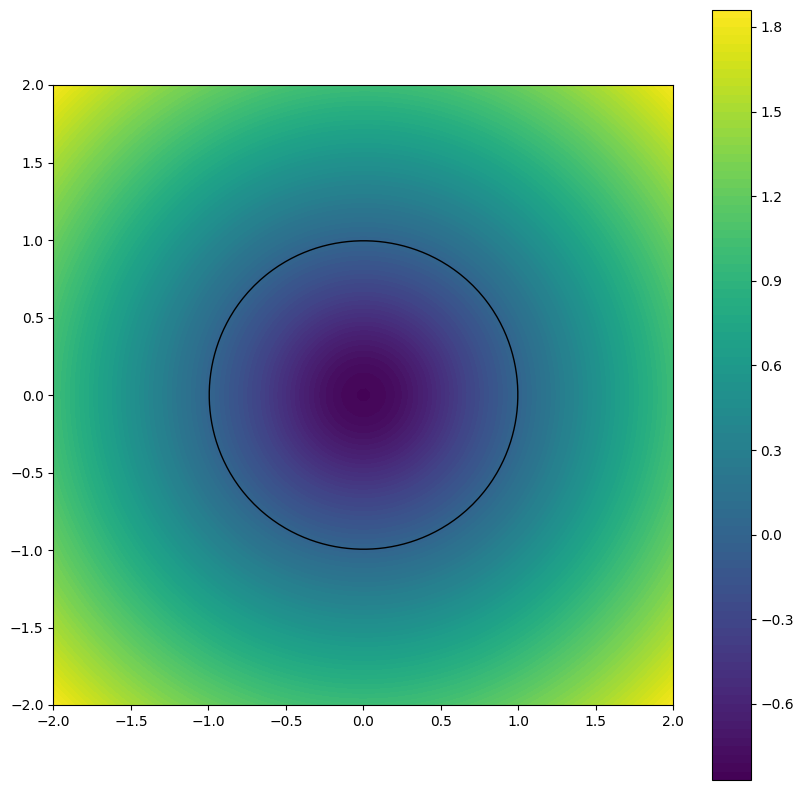

In [35]:
fig = plt.figure(figsize=(10, 10))

ax = fig.add_subplot(111)
ax.set_aspect('equal')
"""
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_xlim(-1.1, -0.9)
ax.set_ylim(-0.1, 0.1)
"""

contourf = ax.contourf(mesh_x, mesh_y, Z_nn.reshape(mesh_x.shape), levels=100, cmap='viridis')
ax.contour(mesh_x, mesh_y, Z_nn.reshape(mesh_x.shape), levels=0, colors='black', linewidths=1)


fig.colorbar(contourf, ax=ax, orientation='vertical')

In [36]:
surf = autoboundedImplicit(partial(neural_network, trained_params), None, 2, 0., classification_flag='bernstein')

In [37]:
surf_lip = sdfImplicit(partial(sdf_circle_jax, radius=1.0))

In [38]:
meshR = meshRefinement(surf_lip, 10, stop_eps=eps, bbox=((-2, 2), (-2, 2)), initial_mesh_resolution=50, max_boxes=25600)

In [39]:
meshR.build()

In [40]:
for lvl, boxes in enumerate(meshR.level_aas):
    print("N boxes at level", lvl, ":", boxes.shape[0])
print("N final pruned boxes:", meshR.level_aas[-1][meshR.level_classes[-1] == 0].shape[0])

N boxes at level 0 : 2500
N boxes at level 1 : 384
N boxes at level 2 : 816
N boxes at level 3 : 1808
N boxes at level 4 : 3600
N boxes at level 5 : 6960
N boxes at level 6 : 14224
N boxes at level 7 : 28496
N boxes at level 8 : 56080
N boxes at level 9 : 112144
N final pruned boxes: 55876


(-0.1, 0.1)

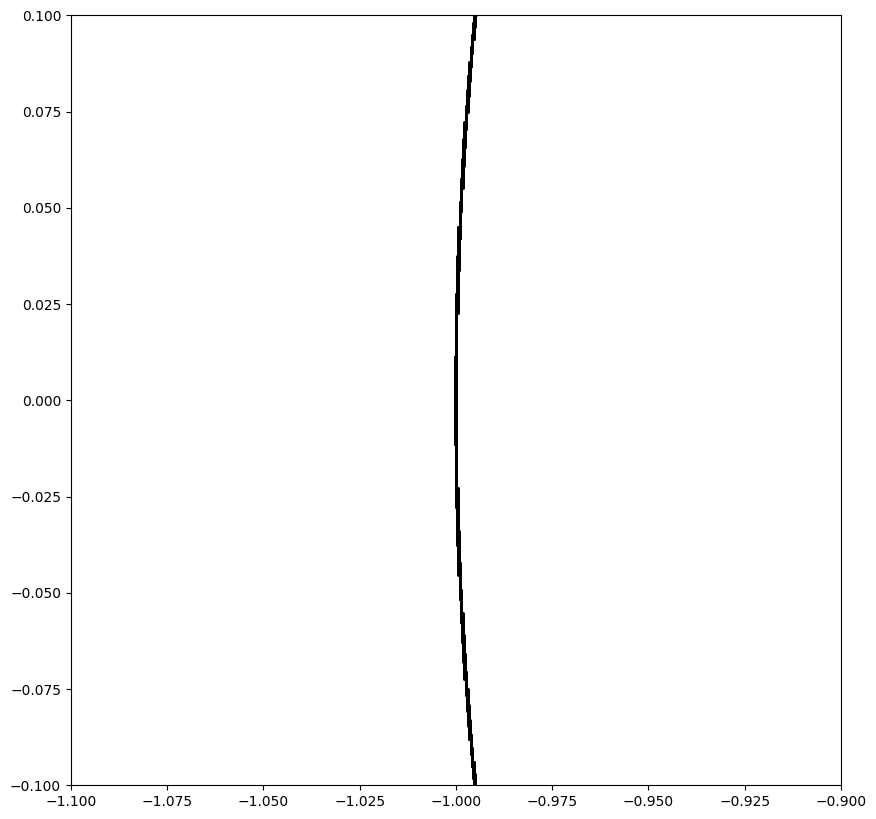

In [42]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)


lvl = -1
Z_sdf = jax.vmap(surf_lip, in_axes=(0,))(X_jnp)

ax.set_aspect('equal')
ax.scatter(meshR.level_aas[lvl][:, 0], meshR.level_aas[lvl][:, 1], s=1, color='black')
#ax.scatter(meshR.level_aas[lvl][:, 0]+0.5*meshR.level_sizes[lvl], meshR.level_aas[lvl][:, 1]+0.5*meshR.level_sizes[lvl], s=1, color='red')
ax.contour(mesh_x, mesh_y, Z_sdf.reshape(mesh_x.shape), levels=0, colors='black', linewidths=1)
ax.set_xlim(-1.1, -0.9)
ax.set_ylim(-0.1, 0.1)

In [22]:
def boundary_condition(position: Array2f) -> Float:
    return 2. - 2.*dr.sin(dr.atan2(position.y, position.x))

def source_term(position: Array2f) -> Float:
    return Float(0.)

In [23]:
kd_surf = KDTreeSurface(None, lambda p1, p2: dr.squared_norm(p1 - p2))
kd_surf.build_kdtree(meshR.level_aas[-1] + (meshR.level_sizes[-1] * jnp.ones(meshR.level_aas[-1].shape[-1]) / 2.))
kd_surf.distance_to_boundary(X_dr)

[0.00332526, 0.00332526, 0.00332526, .. 493562 skipped .., 0.00332526, 0.00332526, 0.00332526]

In [24]:
solver = WoSSolver(kd_surf, boundary_condition, source_term, seed=0, max_steps=1000, eps=1e-3)

X_dr = Array2f(X_walks_jnp_interior.T)
result_mlp = solver.solve(X_dr)

In [25]:
result_mlp.w.jax().shape

(493568,)

In [26]:
X_walks_jnp_interior.shape

(493568, 2)

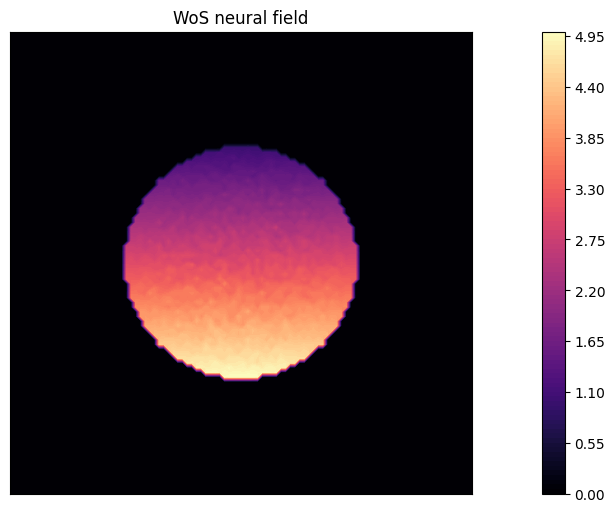

In [35]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(18, 6))

ax = axs
result_jnp = jnp.zeros_like(sdf_values)
result_jnp = result_jnp.at[sdf_values < surf.level_set].set(result_mlp.w.jax())
result_jnp = result_jnp.reshape(-1, nWalks).mean(axis=1)
contourf = ax.contourf(mesh_x, mesh_y, result_jnp.reshape(res, res), levels=100, cmap='magma')

ax.set_title('WoS neural field')
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])
plt.colorbar(contourf, ax=ax)